EXPERIMENT 10
MODEL EVALUATION AND HYPERPARAMETER TUNING

DATASET OVERVIEW
   StudentID  Gender       City CollegeTier Stream Specialisation Hostel  \
0          1    Male  Ahmedabad       Tier2    ECE     Networking     No   
1          2  Female     Mumbai       Tier2    ECE    DataScience    Yes   
2          3    Male    Kolkata       Tier2     IT    DataScience    Yes   
3          4    Male     Jaipur       Tier1     CS             AI     No   
4          5    Male       Pune       Tier2     IT    DataScience    Yes   

  HistoryOfBacklogs  SGPA_Sem1  SGPA_Sem2  ...  Publications  \
0                No       6.02       6.54  ...             0   
1               Yes       5.84       5.12  ...             0   
2                No       4.91       5.29  ...             0   
3                No       7.67       8.03  ...             0   
4                No       8.14       8.97  ...             1   

   AptitudeTestScore  SoftSkillsRating  CodingTestScore  MockInterviewScore  \
0   

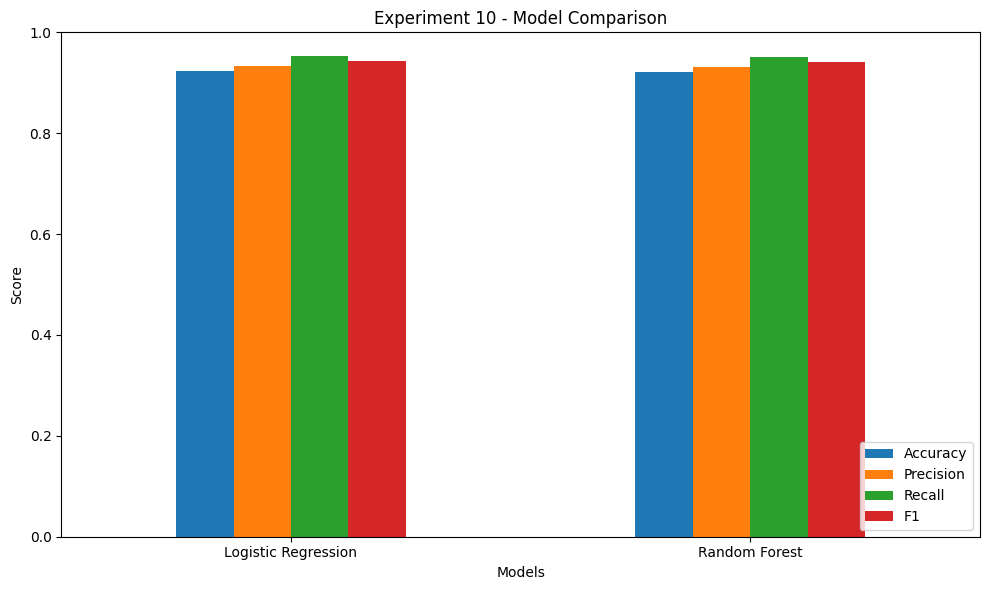


STRATIFIED K-FOLD CROSS VALIDATION

 ACCURACY
Fold scores: [0.92633333 0.9265     0.918      0.92266667 0.914     ]
Mean: 0.9215
Standard deviation: 0.004862555341016107

 PRECISION
Fold scores: [0.93188549 0.93427579 0.92976339 0.93695051 0.92486982]
Mean: 0.9315490016988791
Standard deviation: 0.004111564114385589

 RECALL
Fold scores: [0.9578894  0.95536394 0.94674106 0.94598022 0.94598022]
Mean: 0.9503909657314858
Standard deviation: 0.005161164493028197

 F1
Fold scores: [0.94470853 0.94470219 0.93817542 0.94144372 0.93530592]
Mean: 0.9408671559529042
Standard deviation: 0.0036869747256635214

HYPERPARAMETER TUNING
Fitting 3 folds for each of 6 candidates, totalling 18 fits

Best hyperparameters:
{'model__n_estimators': 120, 'model__min_samples_leaf': 5, 'model__max_depth': 10}

Best cross-validation F1:
0.9410982694688682

TUNED MODEL VALIDATION
Accuracy: 0.9205
Precision: 0.9264619019492026
Recall: 0.9548014000913103
F1: 0.9404181968073146

FINAL MODEL TRAINING

FINAL HELD-OUT 

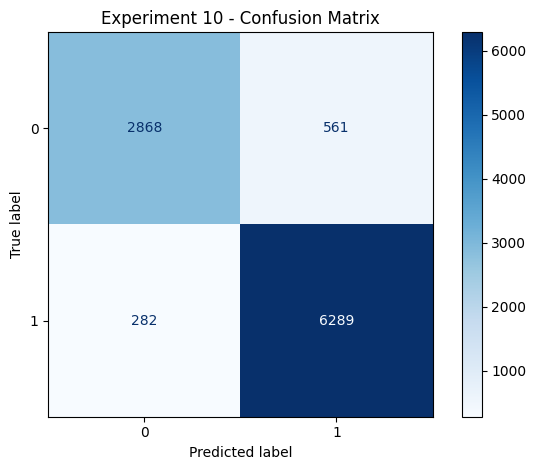


ROC CURVE


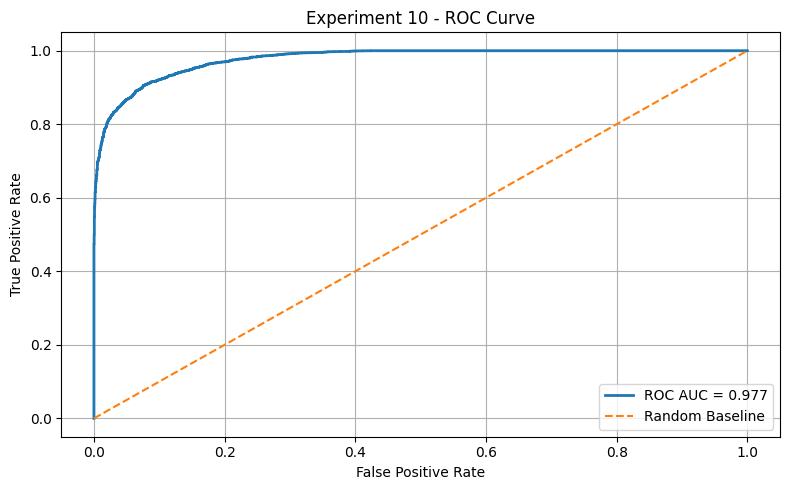


PRECISION RECALL CURVE


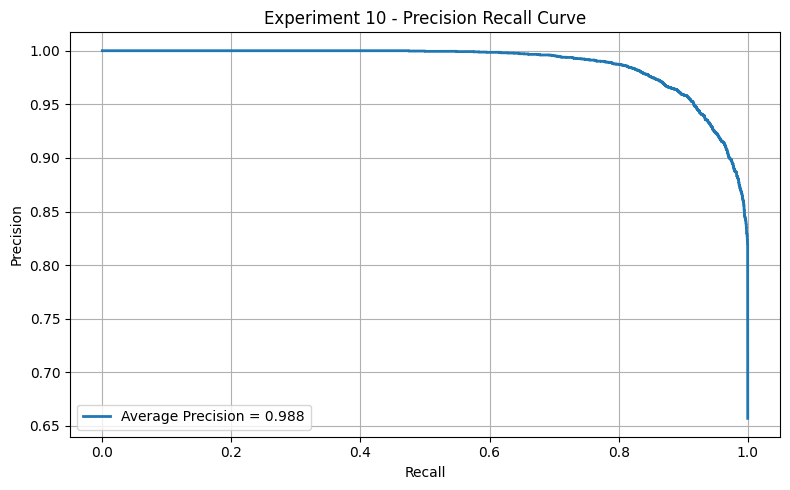


PROBABILITY CALIBRATION


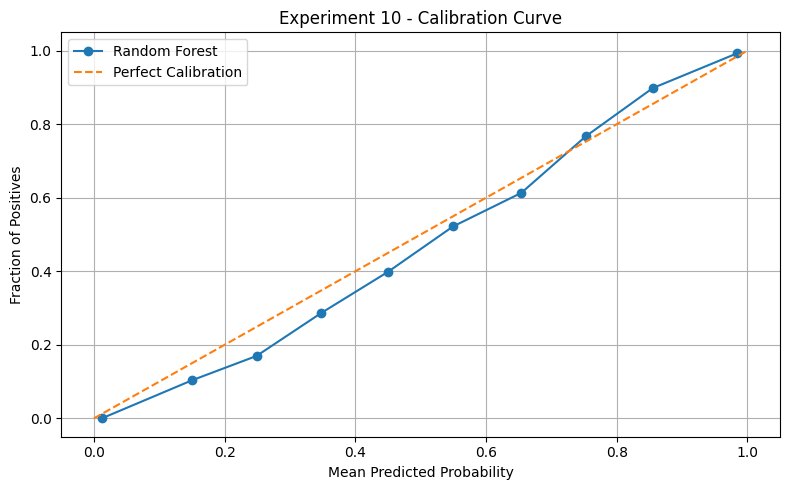


LEARNING CURVE


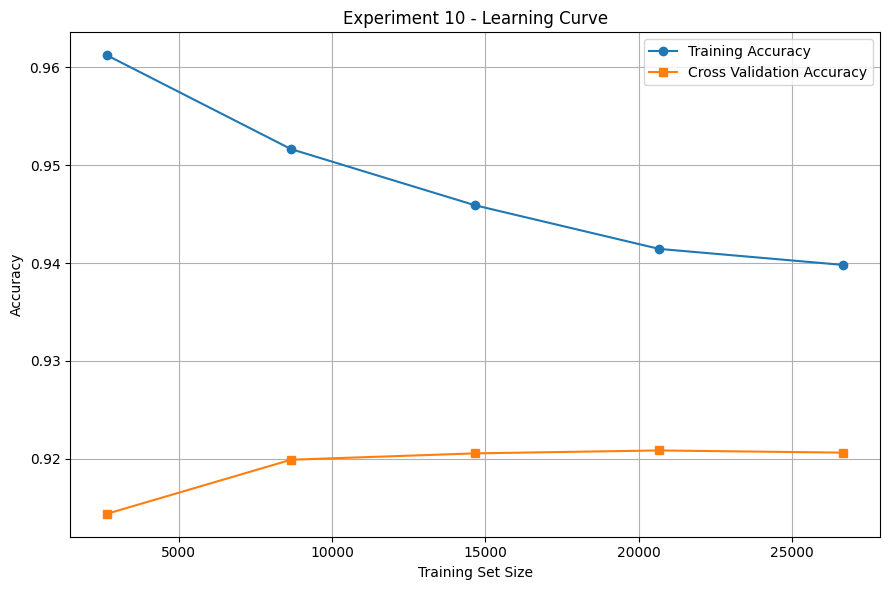


FEATURE IMPORTANCE

Top 15 Important Features:
                        Feature  Importance
7            numeric__SGPA_Sem8    0.110980
6            numeric__SGPA_Sem7    0.105560
8                 numeric__CGPA    0.086132
2            numeric__SGPA_Sem3    0.080245
4            numeric__SGPA_Sem5    0.066409
18  numeric__MockInterviewScore    0.065351
5            numeric__SGPA_Sem6    0.064729
1            numeric__SGPA_Sem2    0.057452
3            numeric__SGPA_Sem4    0.049482
17     numeric__CodingTestScore    0.048941
16    numeric__SoftSkillsRating    0.045754
11            numeric__Projects    0.043568
10         numeric__Internships    0.031993
15   numeric__AptitudeTestScore    0.027920
0            numeric__SGPA_Sem1    0.025838


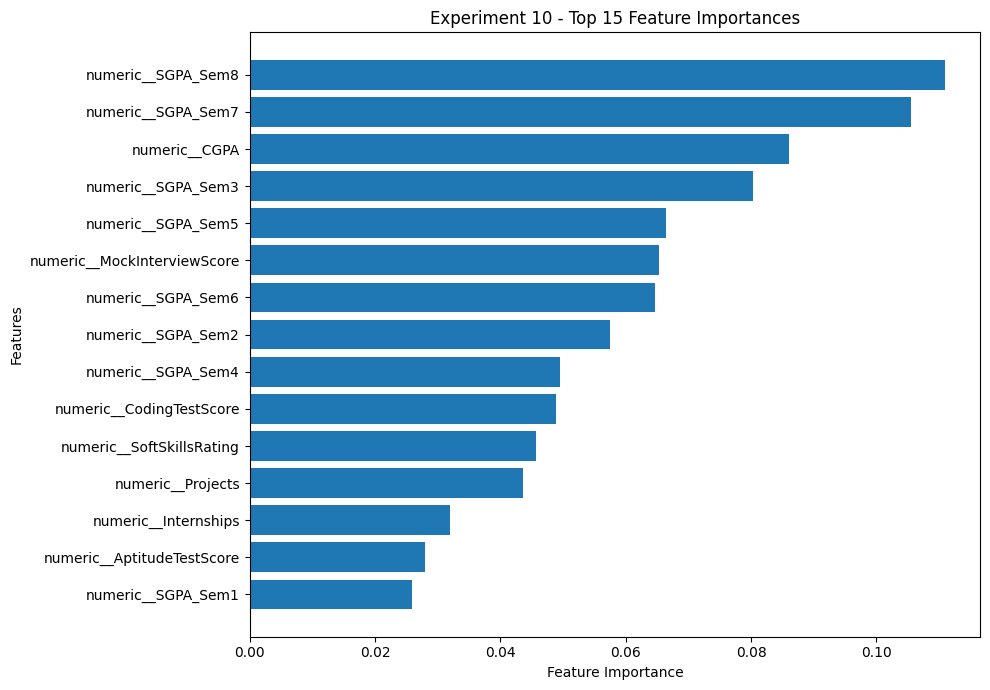


SAVING RESULTS

All results saved successfully!
Experiment 10 completed successfully!


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay, roc_curve,
    roc_auc_score, precision_recall_curve, average_precision_score,
    brier_score_loss
)
from sklearn.calibration import calibration_curve

FILE = 'placement_predict_50k Dataset.csv'
df = pd.read_csv(FILE)

print("EXPERIMENT 10")
print("MODEL EVALUATION AND HYPERPARAMETER TUNING")
print("=" * 60)

print("\nDATASET OVERVIEW")
print(df.head())
print("\nRows and columns:", df.shape)
print("\nDataset information:")
df.info()
print("\nStatistical summary:")
print(df.describe(include='all'))
print("\nTarget balance:")
print(df['PlacementStatus'].value_counts())
print("\nMissing values:")
print(df.isna().sum().sort_values(ascending=False).head(15))

drop_cols = [
    'StudentID', 'PlacementStatus',
    'Salary Package', 'IsAnomaly', 'CGPA_Tier'
]

X = df.drop(columns=drop_cols, errors='ignore')
y = df['PlacementStatus'].astype(int)

print("\nTotal features:", X.shape[1])
print("Target classes:", y.unique())

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval,
    test_size=0.25,
    stratify=y_trainval,
    random_state=42
)

print("\nDATA SPLITTING")
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

print("\nNumerical columns:")
print(num_cols)
print("\nCategorical columns:")
print(cat_cols)

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('numeric', numeric_transformer, num_cols),
    ('categorical', categorical_transformer, cat_cols)
])

baseline = Pipeline([
    ('prep', preprocessor),
    ('model', LogisticRegression(max_iter=1000))
])

forest = Pipeline([
    ('prep', preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

models = {
    'Logistic Regression': baseline,
    'Random Forest': forest
}

validation_results = []

print("\nMODEL TRAINING AND VALIDATION")
print("=" * 60)

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_val)

    acc = accuracy_score(y_val, pred)
    prec = precision_score(y_val, pred, zero_division=0)
    rec = recall_score(y_val, pred, zero_division=0)
    f1 = f1_score(y_val, pred, zero_division=0)

    print("\nModel:", name)
    print("Accuracy:", acc)
    print("Precision:", prec)
    print("Recall:", rec)
    print("F1 Score:", f1)

    validation_results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1': f1
    })

results_df = pd.DataFrame(validation_results)
print("\nMODEL COMPARISON")
print(results_df)

results_df.set_index('Model').plot(
    kind='bar',
    figsize=(10, 6),
    ylim=(0, 1),
    rot=0
)
plt.title('Experiment 10 - Model Comparison')
plt.ylabel('Score')
plt.xlabel('Models')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('exp10_model_comparison.png', dpi=150)
plt.show()

print("\nSTRATIFIED K-FOLD CROSS VALIDATION")

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = cross_validate(
    forest,
    X_train,
    y_train,
    cv=cv,
    scoring=['accuracy', 'precision', 'recall', 'f1'],
    n_jobs=-1
)

for metric in ['accuracy', 'precision', 'recall', 'f1']:
    scores = cv_results['test_' + metric]
    print("\n", metric.upper())
    print("Fold scores:", scores)
    print("Mean:", scores.mean())
    print("Standard deviation:", scores.std())

print("\nHYPERPARAMETER TUNING")
print("=" * 60)

search = RandomizedSearchCV(
    forest,
    param_distributions={
        'model__n_estimators': [80, 120, 160],
        'model__max_depth': [5, 10, 15, None],
        'model__min_samples_leaf': [1, 2, 5]
    },
    n_iter=6,
    cv=StratifiedKFold(
        n_splits=3,
        shuffle=True,
        random_state=42
    ),
    scoring='f1',
    n_jobs=-1,
    random_state=42,
    verbose=1
)

search.fit(X_train, y_train)

print("\nBest hyperparameters:")
print(search.best_params_)
print("\nBest cross-validation F1:")
print(search.best_score_)

chosen = search.best_estimator_

val_pred = chosen.predict(X_val)

print("\nTUNED MODEL VALIDATION")
print("Accuracy:", accuracy_score(y_val, val_pred))
print("Precision:", precision_score(y_val, val_pred, zero_division=0))
print("Recall:", recall_score(y_val, val_pred, zero_division=0))
print("F1:", f1_score(y_val, val_pred, zero_division=0))

print("\nFINAL MODEL TRAINING")

chosen.fit(X_trainval, y_trainval)

y_pred = chosen.predict(X_test)
y_prob = chosen.predict_proba(X_test)[:, 1]

print("\nFINAL HELD-OUT TEST RESULTS")
print("=" * 60)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("PR-AUC:", average_precision_score(y_test, y_prob))
print("Brier Score:", brier_score_loss(y_test, y_prob))

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nCONFUSION MATRIX")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap='Blues'
)
plt.title('Experiment 10 - Confusion Matrix')
plt.tight_layout()
plt.savefig('exp10_confusion_matrix.png', dpi=150)
plt.show()

print("\nROC CURVE")

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(8, 5))
plt.plot(
    fpr, tpr,
    label=f'ROC AUC = {roc_auc:.3f}',
    linewidth=2
)
plt.plot([0, 1], [0, 1], '--', label='Random Baseline')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Experiment 10 - ROC Curve')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('exp10_roc.png', dpi=150)
plt.show()

print("\nPRECISION RECALL CURVE")

precision, recall, thresholds = precision_recall_curve(
    y_test, y_prob
)

pr_auc = average_precision_score(y_test, y_prob)

plt.figure(figsize=(8, 5))
plt.plot(
    recall, precision,
    label=f'Average Precision = {pr_auc:.3f}',
    linewidth=2
)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Experiment 10 - Precision Recall Curve')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('exp10_pr_curve.png', dpi=150)
plt.show()

print("\nPROBABILITY CALIBRATION")

prob_true, prob_pred = calibration_curve(
    y_test,
    y_prob,
    n_bins=10,
    strategy='uniform'
)

plt.figure(figsize=(8, 5))
plt.plot(
    prob_pred,
    prob_true,
    marker='o',
    label='Random Forest'
)
plt.plot(
    [0, 1],
    [0, 1],
    '--',
    label='Perfect Calibration'
)
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.title('Experiment 10 - Calibration Curve')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('exp10_calibration.png', dpi=150)
plt.show()

print("\nLEARNING CURVE")

train_sizes, train_scores, val_scores = learning_curve(
    chosen,
    X_trainval,
    y_trainval,
    cv=3,
    scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 5),
    n_jobs=-1
)

train_mean = np.mean(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)

plt.figure(figsize=(9, 6))
plt.plot(
    train_sizes,
    train_mean,
    marker='o',
    label='Training Accuracy'
)
plt.plot(
    train_sizes,
    val_mean,
    marker='s',
    label='Cross Validation Accuracy'
)
plt.xlabel('Training Set Size')
plt.ylabel('Accuracy')
plt.title('Experiment 10 - Learning Curve')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('exp10_learning_curve.png', dpi=150)
plt.show()

print("\nFEATURE IMPORTANCE")

trained_forest = chosen.named_steps['model']
trained_preprocessor = chosen.named_steps['prep']

feature_names = trained_preprocessor.get_feature_names_out()
importances = trained_forest.feature_importances_

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print("\nTop 15 Important Features:")
print(importance_df.head(15))

top_features = importance_df.head(15)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features['Feature'][::-1],
    top_features['Importance'][::-1]
)
plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.title('Experiment 10 - Top 15 Feature Importances')
plt.tight_layout()
plt.savefig('exp10_feature_importance.png', dpi=150)
plt.show()

print("\nSAVING RESULTS")

results_df.to_csv(
    'exp10_model_comparison.csv',
    index=False
)

importance_df.to_csv(
    'exp10_feature_importance.csv',
    index=False
)

test_results = pd.DataFrame({
    'Actual': y_test.to_numpy(),
    'Predicted': y_pred,
    'Placement_Probability': y_prob
})

test_results.to_csv(
    'exp10_predictions.csv',
    index=False
)

print("\nAll results saved successfully!")
print("Experiment 10 completed successfully!")